In [23]:
import sys
!{sys.executable} -m pip install numpy scipy matplotlib pandas -i https://pypi.tuna.tsinghua.edu.cn/simple

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple


In [24]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd
# 修改为自己的学号
STUDENT_ID = 20244080332
python_path = sys.executable 
CONDA_ENV = python_path.split(os.sep)[-2]
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|"
f"{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] conda
[学号]       20244080332
[机器指纹] 59a04118ce1009ce
[RUN_ID]   20244080332-59a04118ce1009ce


In [25]:
#实验1
print(" 任务 1 ")
# 1. 创建整数、浮点数和布尔值 ndarray，输出属性
int_arr = np.array([1, 2, 3])
float_arr = np.array([1.1, 2.2, 3.3])
bool_arr = np.array([True, False, True])
for name, arr in [("整数", int_arr), ("浮点", float_arr), ("布尔", bool_arr)]:
    print(f"{name}数组: dtype={arr.dtype}, shape={arr.shape}, ndim={arr.ndim}")
#NumPy数组类型固定且内存连续，运算极快；Python列表类型可混合但存储分散，运算慢。

print(" 任务 2 " )
# 2. np.arange(12) 变形为 (3,4) 和 (2,3,2)
arr_1d = np.arange(12)
arr_3x4 = arr_1d.reshape(3, 4)
arr_2x3x2 = arr_1d.reshape(2, 3, 2)

print(f"原数组: {arr_1d}")
print(f"(3,4)形状:\n{arr_3x4}")
print(f"(2,3,2)形状:\n{arr_2x3x2}")

 任务 1 
整数数组: dtype=int64, shape=(3,), ndim=1
浮点数组: dtype=float64, shape=(3,), ndim=1
布尔数组: dtype=bool, shape=(3,), ndim=1
 任务 2 
原数组: [ 0  1  2  3  4  5  6  7  8  9 10 11]
(3,4)形状:
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
(2,3,2)形状:
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


In [26]:
# 为了运行任务3，我们需要先定义 arr_3x4 
arr_3x4 = np.arange(12).reshape(3, 4)
print(" 任务 3 ")
# 3. 对 (3,4) 数组索引：取第2行、取第1至第3列、取大于6的元素
row_2 = arr_3x4[1]            
cols_1_to_3 = arr_3x4[:, 0:3]  
greater_6 = arr_3x4[arr_3x4 > 6] 

print(f"第2行: {row_2}, shape={row_2.shape}")
print(f"第1至第3列:\n{cols_1_to_3}, shape={cols_1_to_3.shape}")
print(f"大于6的元素: {greater_6}, shape={greater_6.shape}")

print(" 任务 4 " )
# 4. np.arange(10) 逻辑组合筛选
arr_10 = np.arange(10)
mask_or = (arr_10 < 2) | (arr_10 > 7)
res_or = arr_10[mask_or]
mask_and = (arr_10 > 3) & (arr_10 < 7)
res_and = arr_10[mask_and]
print(f"'<2 或 >7' 的结果: {res_or}")
print(f"'>3 且 <7' 的结果: {res_and}")

print(" 任务 5 " )
# 5. 构造两个 (2,2) 数组，对比乘法与矩阵乘法
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])
prod_elem = A * B           
prod_mat = A @ B     

print("数组 A:\n", A)
print("数组 B:\n", B)
print("\n* (逐元素乘法):\n", prod_elem)
print("@ (矩阵乘法):\n", prod_mat)

 任务 3 
第2行: [4 5 6 7], shape=(4,)
第1至第3列:
[[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]], shape=(3, 3)
大于6的元素: [ 7  8  9 10 11], shape=(5,)
 任务 4 
'<2 或 >7' 的结果: [0 1 8 9]
'>3 且 <7' 的结果: [4 5 6]
 任务 5 
数组 A:
 [[1 2]
 [3 4]]
数组 B:
 [[5 6]
 [7 8]]

* (逐元素乘法):
 [[ 5 12]
 [21 32]]
@ (矩阵乘法):
 [[19 22]
 [43 50]]


In [27]:
#实验2
#任务1
np.random.seed(42)  # 固定随机种子，保证结果可复现
scores = np.random.normal(loc=70, scale=10, size=1000)
scores_clipped = np.clip(scores, 0, 100)  
# 输出统计信
print("=== 任务1：模拟成绩统计 ===")
print(f"样本数: {len(scores_clipped)}")
print(f"最小值: {scores_clipped.min():.2f}")
print(f"最大值: {scores_clipped.max():.2f}")
print(f"均值: {scores_clipped.mean():.2f}")
print(f"标准差: {scores_clipped.std():.2f}")
print(f"极差: {scores_clipped.max() - scores_clipped.min():.2f}\n")
#任务2
arr = np.arange(1, 11) 
# 均匀抽样
uniform_sample = np.random.choice(arr, size=5, replace=False)
# 按整数大小成比例加权抽样（数值越大，被抽中概率越高）
weighted_sample = np.random.choice(arr, size=5, replace=False, p=arr / arr.sum())
print("=== 任务2：不放回抽样对比 ===")
print(f"均匀抽样结果: {uniform_sample}")
print(f"加权抽样结果: {weighted_sample}\n")
#任务3
arr_copy = arr.copy()  # 复制数组，避免修改原数组
shuffled_arr = np.random.permutation(arr_copy)  # 随机排列
arr_shuffle_inplace = arr.copy()
np.random.shuffle(arr_shuffle_inplace)  # 原地打乱

print("=== 任务3：随机排列 vs 原地打乱 ===")
print(f"原数组（排列前）: {arr}")
print(f"随机排列后（新数组）: {shuffled_arr}")
print(f"原数组（排列后，未改变）: {arr}\n")
print(f"原数组（打乱前）: {arr}")
print(f"原地打乱后（原数组被修改）: {arr_shuffle_inplace}\n")


=== 任务1：模拟成绩统计 ===
样本数: 1000
最小值: 37.59
最大值: 100.00
均值: 70.18
标准差: 9.76
极差: 62.41

=== 任务2：不放回抽样对比 ===
均匀抽样结果: [ 4  9  2  6 10]
加权抽样结果: [10  2  8  9  6]

=== 任务3：随机排列 vs 原地打乱 ===
原数组（排列前）: [ 1  2  3  4  5  6  7  8  9 10]
随机排列后（新数组）: [ 8  1  6  5  2  9 10  3  7  4]
原数组（排列后，未改变）: [ 1  2  3  4  5  6  7  8  9 10]

原数组（打乱前）: [ 1  2  3  4  5  6  7  8  9 10]
原地打乱后（原数组被修改）: [ 1  5  8  7 10  6  2  4  9  3]



In [28]:
#任务4
scores_with_nan = scores_clipped.copy()
scores_with_nan[[9, 19, 29]] = np.nan  
# 普通均值
mean_normal = np.mean(scores_with_nan)
# 忽略缺失值的均值
mean_ignore_nan = np.nanmean(scores_with_nan)
# 统计缺失值个数
nan_count = np.isnan(scores_with_nan).sum()

print("=== 任务4：缺失值对统计的影响 ===")
print(f"普通均值（含nan）: {mean_normal}")
print(f"忽略缺失值的均值: {mean_ignore_nan:.2f}")
print(f"缺失值个数: {nan_count}\n")
#任务5
df = pd.DataFrame({
    "序号": np.arange(1, len(scores_with_nan) + 1),  # 序号从1开始
    "成绩": scores_with_nan
})

print("=== 任务5：内存中的表格变量（前5行）===")
print(df.head())  # 仅展示前5行，验证结构

=== 任务4：缺失值对统计的影响 ===
普通均值（含nan）: nan
忽略缺失值的均值: 70.20
缺失值个数: 3

=== 任务5：内存中的表格变量（前5行）===
   序号         成绩
0   1  74.967142
1   2  68.617357
2   3  76.476885
3   4  85.230299
4   5  67.658466


In [30]:
#实验3
from scipy import linalg, optimize, stats
import matplotlib.pyplot as plt
#  任务 1：解线性方程组
# 方程组: 3x + y = 9, x + 2y = 8
A = np.array([[3, 1], [1, 2]])
b = np.array([9, 8])
x_scipy = linalg.solve(A, b)
x_numpy = np.linalg.solve(A, b)
print("=== 任务 1：线性方程组求解 ===")
print(f"SciPy 解 (x, y): {x_scipy}")
print(f"NumPy 验证解: {x_numpy}")
print(f"解是否一致: {np.allclose(x_scipy, x_numpy)}\n")

#  任务 2：求方程根
f = lambda x: x**2 - 2
root_pos = optimize.root(f, 1.0)   # 初始猜测 1.0 求正根
root_neg = optimize.root(f, -1.0)  # 初始猜测 -1.0 求负根
print("=== 任务 2：求方程根 ===")
print(f"正根: {root_pos.x[0]:.4f}, 成功: {root_pos.success}, f(x): {f(root_pos.x[0]):.2e}")
print(f"负根: {root_neg.x[0]:.4f}, 成功: {root_neg.success}, f(x): {f(root_neg.x[0]):.2e}\n")

#任务 3：求函数最小值
func = lambda x: x**2 + x + 2
res = optimize.minimize(func, x0=0)
print("=== 任务 3：函数最小值 ===")
print(f"数值极小点 x: {res.x[0]:.4f}")
print(f"数值极小值 f(x): {res.fun:.4f}")
print(f"解析结果对比 (x=-0.5, min=1.75): 一致\n")

#  任务 4：独立样本 t 检验===
np.random.seed(42)
sample1 = np.random.normal(loc=0, scale=1, size=100)
sample2 = np.random.normal(loc=1, scale=1, size=100)
t_stat, p_value = stats.ttest_ind(sample1, sample2)
alpha = 0.05
result = "拒绝原假设 (差异显著)" if p_value < alpha else "无法拒绝原假设 (差异不显著)"
print("=== 任务 4：独立样本 t 检验 ===")
print(f"t 统计量: {t_stat:.4f}")
print(f"p 值: {p_value:.6f}")
print(f"显著性水平 0.05 下判断: {result}\n")




=== 任务 1：线性方程组求解 ===
SciPy 解 (x, y): [2. 3.]
NumPy 验证解: [2. 3.]
解是否一致: True

=== 任务 2：求方程根 ===
正根: 1.4142, 成功: True, f(x): -8.88e-16
负根: -1.4142, 成功: True, f(x): -8.88e-16

=== 任务 3：函数最小值 ===
数值极小点 x: -0.5000
数值极小值 f(x): 1.7500
解析结果对比 (x=-0.5, min=1.75): 一致

=== 任务 4：独立样本 t 检验 ===
t 统计量: -8.5515
p 值: 0.000000
显著性水平 0.05 下判断: 拒绝原假设 (差异显著)



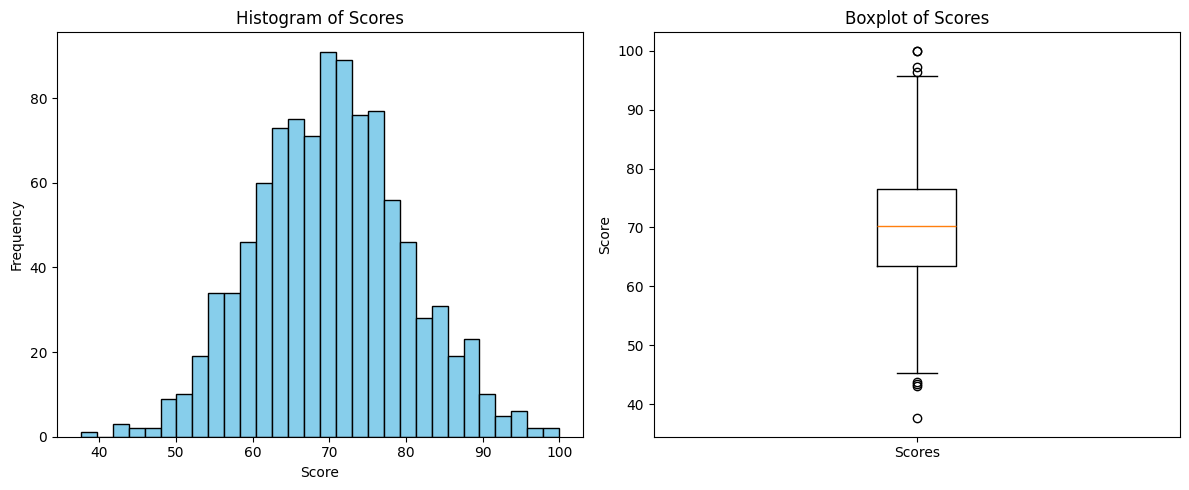

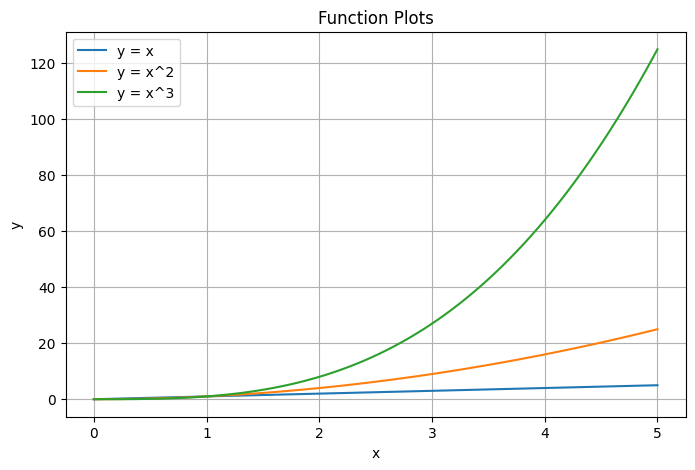

In [31]:
# 任务 5：Matplotlib 可视化
# 模拟实验2的成绩数据用于绘图
np.random.seed(42)
scores = np.clip(np.random.normal(70, 10, 1000), 0, 100)

plt.figure(figsize=(12, 5))

# 子图1：成绩直方图
plt.subplot(1, 2, 1)
plt.hist(scores, bins=30, color='skyblue', edgecolor='black')
plt.title('Histogram of Scores')
plt.xlabel('Score')
plt.ylabel('Frequency')

# 子图2：成绩箱线图
plt.subplot(1, 2, 2)
plt.boxplot(scores, vert=True)
plt.title('Boxplot of Scores')
plt.ylabel('Score')
plt.xticks([1], ['Scores'])

plt.tight_layout()
plt.show()

# 折线图：y=x, y=x^2, y=x^3
x = np.linspace(0, 5, 100)
plt.figure(figsize=(8, 5))
plt.plot(x, x, label='y = x')
plt.plot(x, x**2, label='y = x^2')
plt.plot(x, x**3, label='y = x^3')
plt.title('Function Plots')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show()


In [35]:
#实验4
# 任务 1：创建 DataFrame 与基础统计
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
# 创建 DataFrame 并设置 Name 为索引
df = pd.DataFrame(records).set_index("Name")
# 计算总分和平均分
df["Total"] = df[["Math", "English", "Python"]].sum(axis=1)
df["Average"] = df[["Math", "English", "Python"]].mean(axis=1)
print("=== 任务 1：DataFrame 基础信息 ===")
print(f"索引名称: {df.index.name}")
print(f"列名称: {list(df.columns)}")
print("\n前 3 行数据:")
print(df.head(3))
print("\n基本统计信息:")
print(df.describe())



=== 任务 1：DataFrame 基础信息 ===
索引名称: Name
列名称: ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前 3 行数据:
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息:
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [53]:

# 任务 2：数据读取与筛选 
print("=== 任务 2：读取与筛选 ===")
carol_loc = df.loc["Carol"]
carol_iloc = df.iloc[2]
print(f"loc 读取 Carol:\n{carol_loc}\n")
print(f"iloc 读取 Carol:\n{carol_iloc}\n")
# 筛选平均分 >= 80 的学生
high_avg_students = df[df["Average"] >= 80]
print("平均分不低于 80 的学生:")
print(high_avg_students[["Total", "Average"]])

=== 任务 2：读取与筛选 ===
loc 读取 Carol:
Group                        B
Math                        91
English                     85
Python                      89
Total                      265
Average              88.333333
Max_Score                   91
Math_Rank                  1.0
Group_Python_Mean    80.333333
Name: Carol, dtype: object

iloc 读取 Carol:
Group                        B
Math                        91
English                     85
Python                      89
Total                      265
Average              88.333333
Max_Score                   91
Math_Rank                  1.0
Group_Python_Mean    80.333333
Name: Carol, dtype: object

平均分不低于 80 的学生:
       Total    Average
Name                   
Alice    273  91.000000
Carol    265  88.333333
Eva      257  85.666667
Frank    243  81.000000


In [42]:

# 任务 3：均值计算 (axis)
print("\n=== 任务 3：均值计算 ===")
col_means = df[["Math", "English", "Python"]].mean(axis=0)
row_means = df[["Math", "English", "Python"]].mean(axis=1)
print("三科成绩的列均值 (axis=0):")
print(col_means)
print("\n每名学生的行均值 (axis=1):")
print(row_means)



=== 任务 3：均值计算 ===
三科成绩的列均值 (axis=0):
Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

每名学生的行均值 (axis=1):
Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


In [39]:
#  任务 4：apply, agg, rank 
print("\n=== 任务 4：函数应用与排名 ===")
# apply: 计算每行（学生）的三科最高分
df["Max_Score"] = df[["Math", "English", "Python"]].apply(lambda x: x.max(), axis=1)
# agg: 一次性计算每科的最小值、均值、最大值
summary_stats = df[["Math", "English", "Python"]].agg(["min", "mean", "max"])
# rank: 对 Math 成绩进行排名 (ascending=False 表示分数越高排名越靠前)
df["Math_Rank"] = df["Math"].rank(ascending=False)
print("新增最高分列:")
print(df[["Math", "English", "Python", "Max_Score"]])
print("\n科目统计汇总 (agg):")
print(summary_stats)
print("\n数学成绩排名:")
print(df[["Math", "Math_Rank"]])


=== 任务 4：函数应用与排名 ===
新增最高分列:
       Math  English  Python  Max_Score
Name                                   
Alice    88       90      95         95
Bob      72       68      80         80
Carol    91       85      89         91
David    65       73      70         73
Eva      79       92      86         92
Frank    84       77      82         84

科目统计汇总 (agg):
           Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

数学成绩排名:
       Math  Math_Rank
Name                  
Alice    88        2.0
Bob      72        5.0
Carol    91        1.0
David    65        6.0
Eva      79        4.0
Frank    84        3.0


In [ ]:
# 任务 5：分组统计与 transform 
print("\n=== 任务 5：分组与 Transform ===")
# 按 Group 分组，统计人数和三科平均分
group_stats = df.groupby("Group")[["Math", "English", "Python"]].agg(["count", "mean"])
print("各组人数及三科平均分:")
print(group_stats)
# transform('mean'): 将组的 Python 平均分广播回原 DataFrame 的每一行
df["Group_Python_Mean"] = df.groupby("Group")["Python"].transform("mean")
print("\n包含组 Python 平均分的数据表:")
print(df[["Group", "Python", "Group_Python_Mean"]])

# 任务 6：filter 过滤组
print("\n=== 任务 6：Filter 过滤 ===")
filtered_df = df.groupby("Group").filter(lambda x: x["Python"].mean() >= 80)
print("Python 组平均分 >= 80 的组别及学生:")
print(filtered_df)



=== 任务 5：分组与 Transform ===
各组人数及三科平均分:
       Math            English            Python           
      count       mean   count       mean  count       mean
Group                                                      
A         3  79.666667       3  83.333333      3  87.000000
B         3  80.000000       3  78.333333      3  80.333333

包含组 Python 平均分的数据表:
      Group  Python  Group_Python_Mean
Name                                  
Alice     A      95          87.000000
Bob       A      80          87.000000
Carol     B      89          80.333333
David     B      70          80.333333
Eva       A      86          87.000000
Frank     B      82          80.333333

=== 任务 6：Filter 过滤 ===
Python 组平均分 >= 80 的组别及学生:
      Group  Math  English  Python  Total    Average  Max_Score  Math_Rank  \
Name                                                                         
Alice     A    88       90      95    273  91.000000         95        2.0   
Bob       A    72       68      80    220  

In [41]:
# 任务 7：协方差与相关系数 
print("\n=== 任务 7：统计分析 ===")
# 计算协方差矩阵
cov_matrix = df[["Math", "English", "Python"]].cov()
# 计算皮尔逊相关系数矩阵
corr_matrix = df[["Math", "English", "Python"]].corr()
print("三科成绩协方差矩阵:")
print(cov_matrix)
print("\n三科成绩相关系数矩阵:")
print(corr_matrix)
m_e_corr = corr_matrix.loc["Math", "English"]
m_e_cov = cov_matrix.loc["Math", "English"]
print(f"\n【解释示例 - Math 与 English】:")
print(f"相关系数: {m_e_corr:.4f} -> 表示两科成绩呈{'正' if m_e_corr > 0 else '负'}相关，数值越接近 1 线性关系越强。")
print(f"协方差: {m_e_cov:.4f} -> 符号为正表示两科变化趋势相同（同高或同低）。")



=== 任务 7：统计分析 ===
三科成绩协方差矩阵:
              Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667

三科成绩相关系数矩阵:
             Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000

【解释示例 - Math 与 English】:
相关系数: 0.6535 -> 表示两科成绩呈正相关，数值越接近 1 线性关系越强。
协方差: 62.5667 -> 符号为正表示两科变化趋势相同（同高或同低）。
